<a href="https://colab.research.google.com/github/cynthy1992/Super-Store-Sales-Analysis-Dashboard/blob/main/task_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install pandas numpy matplotlib seaborn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [7]:
df = pd.read_csv("/superstore_sales.csv")

In [8]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [9]:
df.shape
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         10800 non-null  object 
 1   Order ID       10800 non-null  object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9983 non-null   float64
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quanti

,Postal Code,Sales,Quantity,Discount,Profit
count,9983.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,55245.233297,229.858001,3.789574,0.156203,28.656896
std,32038.715955,623.245101,2.225110,0.206452,234.260108
min,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,57103.000000,54.490000,3.000000,0.200000,8.666500
75%,90008.000000,209.940000,5.000000,0.200000,29.364000
max,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [10]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')

In [11]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,806
Ship Date,806
Ship Mode,806
Customer ID,806
Customer Name,806
Segment,806
Country,806
City,806


In [12]:
df = df.dropna(subset=['Order Date'])

In [13]:
df.isnull().sum()

,0
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


In [14]:
df.duplicated().sum()

np.int64(0)

In [18]:
df['order date'] = pd.to_datetime(
    df['Order Date'],
    errors = 'coerce',
)

In [19]:
df['Order Date'].dtype

dtype('O')

In [23]:
df['Order Date'].dtype

dtype('O')

In [25]:
df['Order Date'] = pd.to_datetime(
    df['Order Date'],
    errors='coerce'
)

In [26]:
df['Order Date'].dtype

dtype('<M8[ns]')

In [27]:
df['Year'] = df['Order Date'].dt.year

In [28]:
df['Month'] = df['Order Date'].dt.month

In [29]:
df['Year-Month'] = df['Order Date'].dt.to_period('M')

In [30]:
df[['Order Date', 'Year', 'Month', 'Year-Month']].head(10)

,Order Date,Year,Month,Year-Month
0,2017-11-08,2017,11,2017-11
1,2017-11-08,2017,11,2017-11
2,2017-06-12,2017,6,2017-06
3,2016-10-11,2016,10,2016-10
4,2016-10-11,2016,10,2016-10
5,2015-06-09,2015,6,2015-06
6,2015-06-09,2015,6,2015-06
7,2015-06-09,2015,6,2015-06
8,2015-06-09,2015,6,2015-06
9,2015-06-09,2015,6,2015-06


In [31]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'order date',
       'Year', 'Month', 'Year-Month'],
      dtype='object')

In [32]:
df['Year-Month'] = (
    df['Order Date'].dt.to_period('M').dt.to_timestamp()
)

In [33]:
df.info()
df.isnull().sum()
df.head()

<class 'pandas.core.frame.DataFrame'>
Index: 9994 entries, 0 to 9993
Data columns (total 25 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   object        
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   object        
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9983 non-null   float64       
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 non-nu

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,order date,Year,Month,Year-Month
0,1,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017-11-08,2017,11,2017-11-01
1,2,CA-2017-152156,2017-11-08,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017-11-08,2017,11,2017-11-01
2,3,CA-2017-138688,2017-06-12,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017-06-12,2017,6,2017-06-01
3,4,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016-10-11,2016,10,2016-10-01
4,5,US-2016-108966,2016-10-11,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016-10-11,2016,10,2016-10-01


In [34]:
df.to_csv('cleaned_superstore_sales.csv', index=False)

In [35]:
category_analysis = df.groupby('Category').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

In [40]:
category_analysis

,Category,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,741999.7953,18451.2728,8028.0
1,Office Supplies,719047.0320,122490.8008,22906.0
2,Technology,836154.0330,145454.9481,6939.0


In [36]:
region_analysis = df.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum')
).reset_index()

In [41]:
region_analysis

,Region,Total_Sales,Total_Profit
0,Central,501239.8908,39706.3625
1,East,678781.2400,91522.7800
2,South,391721.9050,46749.4303
3,West,725457.8245,108418.4489


In [37]:
segment_analysis = df.groupby('Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Orders=('Order ID', 'nunique')
).reset_index()

In [42]:
segment_analysis

,Segment,Total_Sales,Total_Profit,Total_Orders
0,Consumer,1.161401e+06,134119.2092,2586
1,Corporate,7.061464e+05,91979.1340,1514
2,Home Office,4.296531e+05,60298.6785,909


In [38]:
combined_analysis = df.groupby(
    ['Category', 'Region', 'Segment']
).agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Total_Quantity=('Quantity', 'sum')
).reset_index()

In [39]:
combined_analysis.head(20)

,Category,Region,Segment,Total_Sales,Total_Profit,Total_Quantity
0,Furniture,Central,Consumer,86229.2190,-3994.4342,952.0
1,Furniture,Central,Corporate,52085.6018,2321.9939,542.0
2,Furniture,Central,Home Office,25482.3430,-1198.6091,333.0
3,Furniture,East,Consumer,114211.8020,2038.1122,1114.0
4,Furniture,East,Corporate,64209.0460,342.1257,723.0
5,Furniture,East,Home Office,29870.3560,665.9279,377.0
6,Furniture,South,Consumer,70800.2040,4616.7326,695.0
7,Furniture,South,Corporate,29645.0315,952.0303,415.0
8,Furniture,South,Home Office,16853.4485,1202.4432,181.0
9,Furniture,West,Consumer,119808.0870,4330.6680,1405.0


In [43]:
combined_analysis.to_csv(
    'sales_profit_summary.csv',
    index=False
)

In [51]:
df['Month_Name'] = df['Order Date'].dt.strftime('%B')

In [52]:
df['Month_Number'] = df['Order Date'].dt.month

In [53]:
monthly_sales = df.groupby(
    ['Month_Number', 'Month_Name']
).agg(
    Total_Sales=('Sales', 'sum')
).reset_index()

monthly_sales = monthly_sales.sort_values('Month_Number')

In [56]:
monthly_sales.head()

,Month_Number,Month_Name,Total_Sales
0,1,January,94924.8356
1,2,February,59751.2514
2,3,March,205005.4888
3,4,April,137762.1286
4,5,May,155028.8117


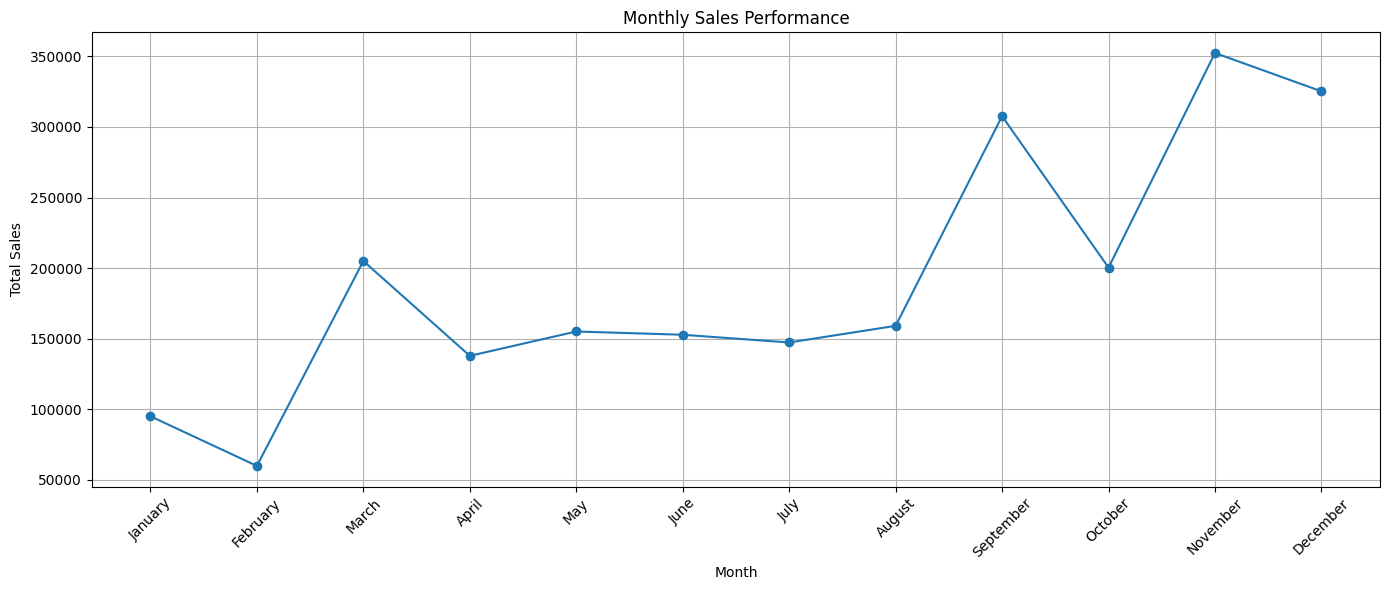

In [57]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Month_Name'],
    monthly_sales['Total_Sales'],
    marker='o'
)

plt.title('Monthly Sales Performance')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

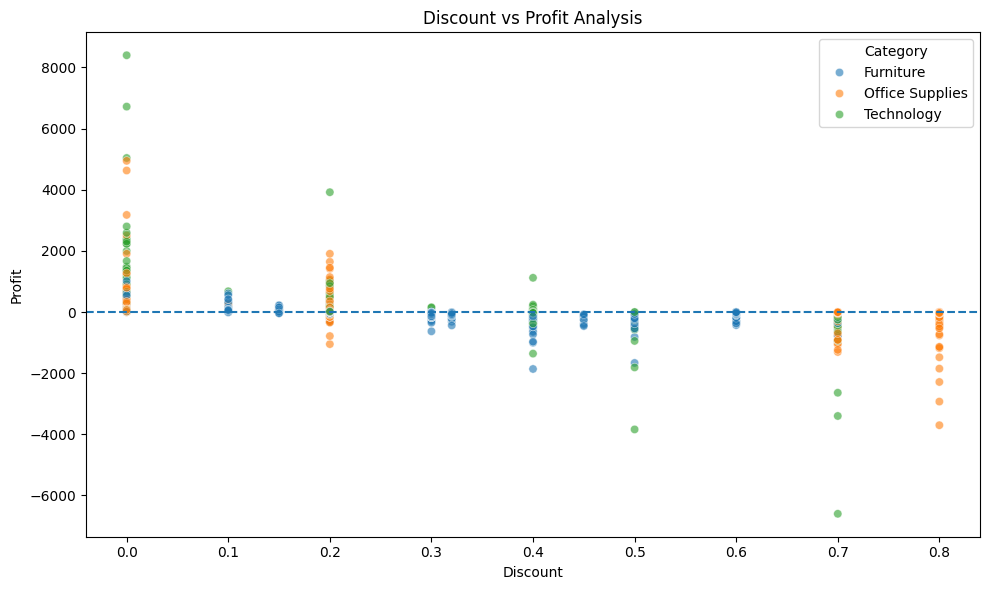

In [58]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x='Discount',
    y='Profit',
    hue='Category',
    alpha=0.6
)

plt.title('Discount vs Profit Analysis')
plt.xlabel('Discount')
plt.ylabel('Profit')

plt.axhline(0, linestyle='--')
plt.tight_layout()
plt.show()

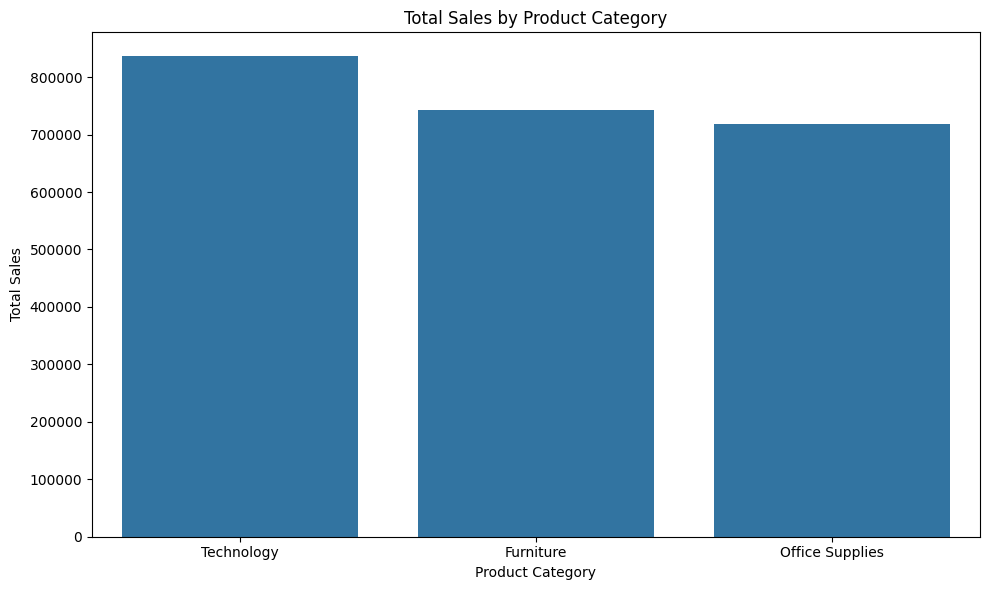

In [59]:
category_sales = df.groupby('Category')['Sales'].sum().reset_index()

category_sales = category_sales.sort_values(
    by='Sales', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales,
    x='Category',
    y='Sales'
)

plt.title('Total Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.tight_layout()
plt.show()

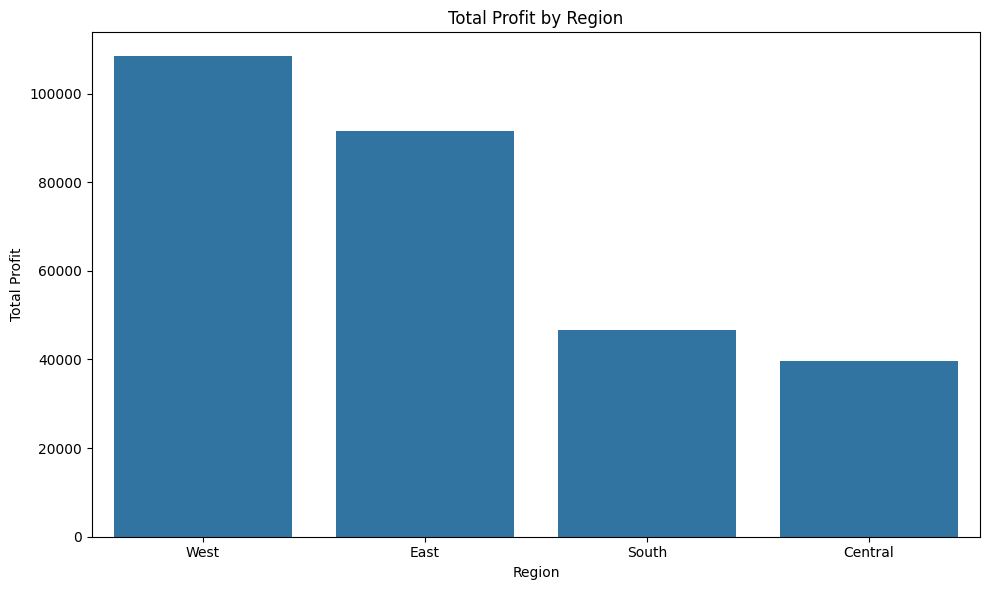

In [60]:
region_profit = df.groupby('Region')['Profit'].sum().reset_index()

region_profit = region_profit.sort_values(
    by='Profit', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_profit,
    x='Region',
    y='Profit'
)

plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Total Profit')

plt.tight_layout()
plt.show()

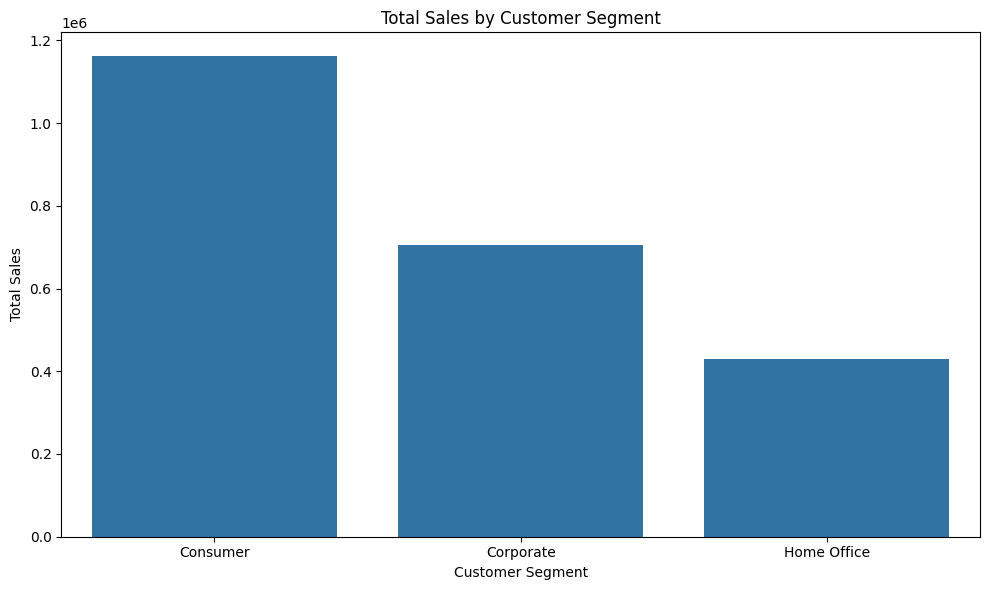

In [61]:
segment_sales = df.groupby('Segment')['Sales'].sum().reset_index()

segment_sales = segment_sales.sort_values(
    by='Sales', ascending=False
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=segment_sales,
    x='Segment',
    y='Sales'
)

plt.title('Total Sales by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Sales')

plt.tight_layout()
plt.show()

In [63]:
heatmap_data = df.pivot_table(
    index='Category',
    columns='Region',
    values='Profit',
    aggfunc='sum'
)

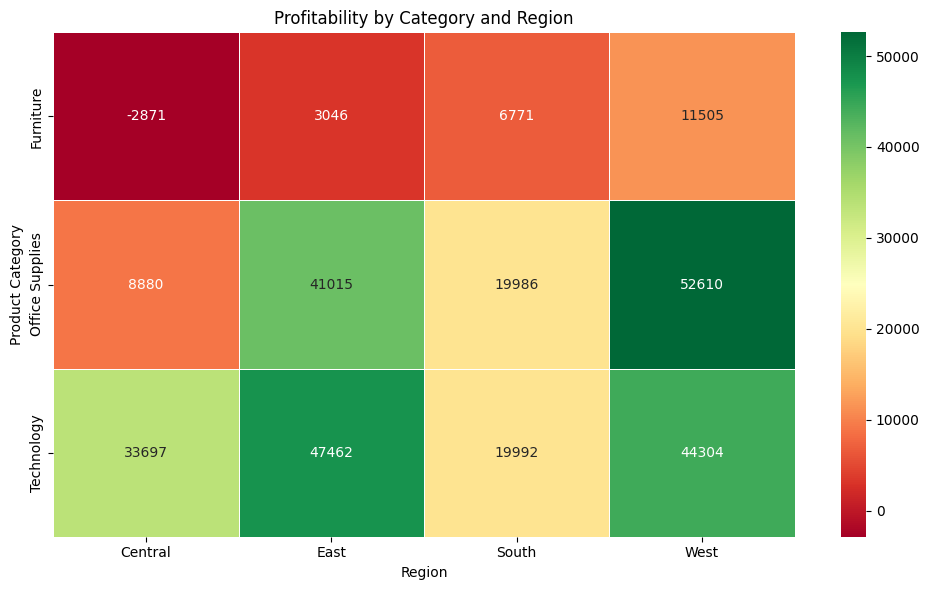

In [65]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0f',
    cmap='RdYlGn',
    linewidths=0.5
)

plt.title('Profitability by Category and Region')
plt.xlabel('Region')
plt.ylabel('Product Category')

plt.tight_layout()
plt.show()

In [66]:
print("SALES BY CATEGORY")
display(category_sales)

print("PROFIT BY REGION")
display(region_profit)

print("SALES BY CUSTOMER SEGMENT")
display(segment_sales)

print("PROFIT HEATMAP DATA")
display(heatmap_data)

SALES BY CATEGORY


,Category,Sales
2,Technology,836154.0330
0,Furniture,741999.7953
1,Office Supplies,719047.0320


PROFIT BY REGION


,Region,Profit
3,West,108418.4489
1,East,91522.7800
2,South,46749.4303
0,Central,39706.3625


SALES BY CUSTOMER SEGMENT


,Segment,Sales
0,Consumer,1.161401e+06
1,Corporate,7.061464e+05
2,Home Office,4.296531e+05


PROFIT HEATMAP DATA


Region,Central,East,South,West
Category,,,,
Furniture,-2871.0494,3046.1658,6771.2061,11504.9503
Office Supplies,8879.9799,41014.5791,19986.3928,52609.8490
Technology,33697.4320,47462.0351,19991.8314,44303.6496


In [67]:
plt.savefig(
    'sales_by_category.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [69]:
plt.close('all')

In [76]:
monthly_sales = df.groupby(
    df['Order Date'].dt.month
)['Sales'].sum()

monthly_sales.index = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

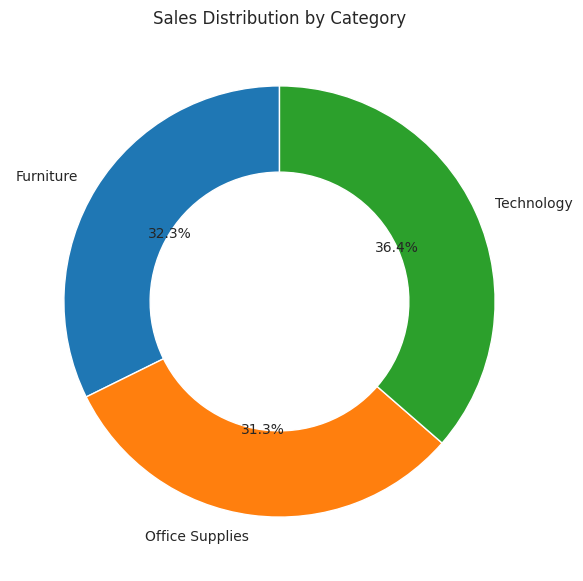

In [77]:
category_sales = df.groupby('Category')['Sales'].sum()

plt.figure(figsize=(7, 7))

plt.pie(
    category_sales,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

plt.title('Sales Distribution by Category')
plt.show()

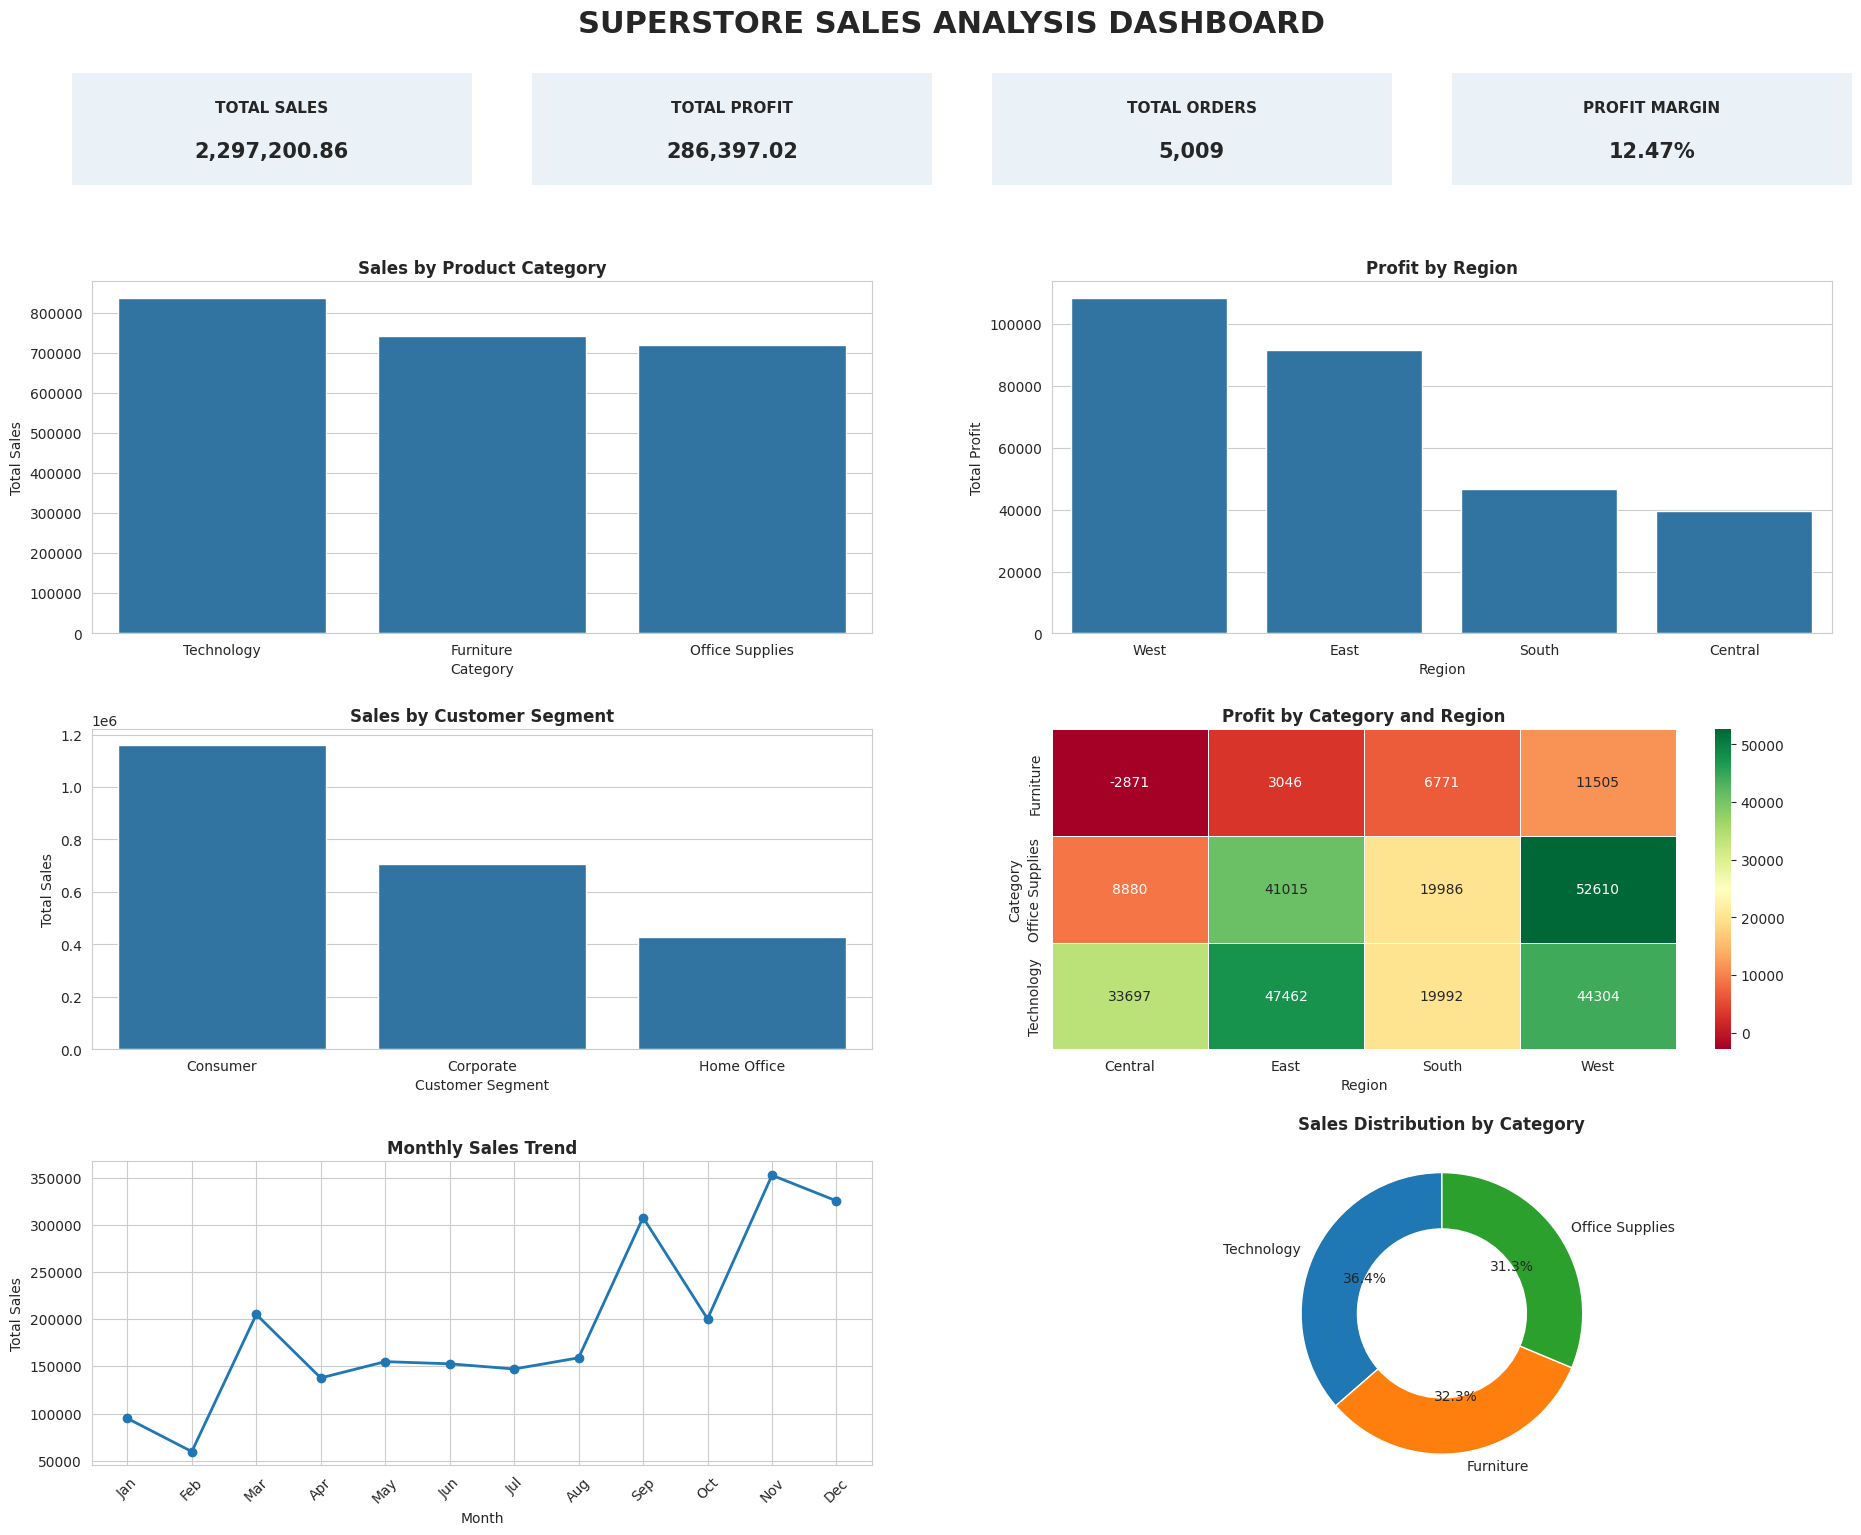

In [78]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

# Create dashboard
fig = plt.figure(figsize=(20, 16))

fig.suptitle(
    'SUPERSTORE SALES ANALYSIS DASHBOARD',
    fontsize=22,
    fontweight='bold',
    y=0.98
)

# KPI calculations
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()
profit_margin = (total_profit / total_sales) * 100

# KPI cards
kpi_data = [
    ('TOTAL SALES', f'{total_sales:,.2f}'),
    ('TOTAL PROFIT', f'{total_profit:,.2f}'),
    ('TOTAL ORDERS', f'{total_orders:,}'),
    ('PROFIT MARGIN', f'{profit_margin:.2f}%')
]

for i, (label, value) in enumerate(kpi_data):
    ax = fig.add_axes([0.06 + i * 0.23, 0.87, 0.20, 0.07])
    ax.set_facecolor('#EAF2F8')
    ax.text(0.5, 0.65, label, ha='center',
            fontsize=11, fontweight='bold')
    ax.text(0.5, 0.25, value, ha='center',
            fontsize=15, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# Prepare summary data
category_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)

region_profit = df.groupby('Region')['Profit'].sum().sort_values(ascending=False)

segment_sales = df.groupby('Segment')['Sales'].sum().sort_values(ascending=False)

heatmap_data = df.pivot_table(
    index='Category',
    columns='Region',
    values='Profit',
    aggfunc='sum'
)

# Monthly sales
monthly_sales = df.groupby(
    df['Order Date'].dt.month
)['Sales'].sum()

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

monthly_sales.index = [
    month_names[i-1] for i in monthly_sales.index
]

# Chart 1: Sales by Category
ax1 = fig.add_axes([0.07, 0.59, 0.39, 0.22])

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    ax=ax1
)

ax1.set_title('Sales by Product Category', fontweight='bold')
ax1.set_xlabel('Category')
ax1.set_ylabel('Total Sales')

# Chart 2: Profit by Region
ax2 = fig.add_axes([0.55, 0.59, 0.39, 0.22])

sns.barplot(
    x=region_profit.index,
    y=region_profit.values,
    ax=ax2
)

ax2.set_title('Profit by Region', fontweight='bold')
ax2.set_xlabel('Region')
ax2.set_ylabel('Total Profit')

# Chart 3: Sales by Segment
ax3 = fig.add_axes([0.07, 0.33, 0.39, 0.20])

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values,
    ax=ax3
)

ax3.set_title('Sales by Customer Segment', fontweight='bold')
ax3.set_xlabel('Customer Segment')
ax3.set_ylabel('Total Sales')

# Chart 4: Profit Heatmap
ax4 = fig.add_axes([0.55, 0.33, 0.39, 0.20])

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.0f',
    cmap='RdYlGn',
    linewidths=0.5,
    ax=ax4
)

ax4.set_title('Profit by Category and Region', fontweight='bold')

# Chart 5: Monthly Sales Line Chart
ax5 = fig.add_axes([0.07, 0.07, 0.39, 0.19])

ax5.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker='o',
    linewidth=2
)

ax5.set_title('Monthly Sales Trend', fontweight='bold')
ax5.set_xlabel('Month')
ax5.set_ylabel('Total Sales')
ax5.tick_params(axis='x', rotation=45)
ax5.grid(True)

# Chart 6: Donut Chart
ax6 = fig.add_axes([0.55, 0.055, 0.39, 0.22])

ax6.pie(
    category_sales.values,
    labels=category_sales.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4}
)

ax6.set_title('Sales Distribution by Category', fontweight='bold')

# Display dashboard
plt.show()

# Save dashboard
fig.savefig(
    'Superstore_Complete_Dashboard.png',
    dpi=300,
    bbox_inches='tight'
)



# SUPERSTORE SALES DATA ANALYSIS

## 1. Project Overview
This project analyzes Superstore sales data to understand
revenue performance, profitability, customer segments,
product categories, and regional performance.

## 2. Project Objectives
- Clean and prepare the sales dataset.
- Analyze sales and profit by product category.
- Compare regional sales performance.
- Evaluate customer segment contributions.
- Examine monthly sales trends.
- Investigate the relationship between discounts and profit.

## 3. Data Cleaning
- Removed records with missing Order Dates.
- Checked for duplicate records.
- Converted Order Date into datetime format.
- Extracted Year, Month, and Year-Month.
- Reviewed missing values.

## 4. Key Performance Indicators
- Total Sales
- Total Profit
- Total Orders
- Profit Margin

## 5. Business Insights
### Product Category Performance
Technology leads profit at $145,455 (50.8% of total profit) and ~36.4% of sales. Office Supplies follows with $122,491 (42.8%) at ~31.3% of sales. Furniture brings in ~32.3% of sales but only $18,451 (6.4%) of profit, weighed down by a -$2,871 loss in the Central region.

### Regional Performance
Total profit is $286,397, heavily concentrated in the West ($108,419, 37.9%) and East ($91,523, 32.0%), which together generate $199,942 (69.8%). The South ($46,749, 16.3%) and Central ($39,706, 13.9%) make up the remaining $86,455 (30.2%), with Central profit relying 84.9% on Technology ($33,697).

### Customer Segment Performance
The Consumer segment drives the most revenue—roughly 1.6x Corporate and 2.8x Home Office—making it the primary top-line growth engine.

### Monthly Sales Trends
Sales start low in January–February (lowest in February), stay relatively flat from April–August, and surge from September to a peak above $300,000/month in November–December.

### Discount and Profit Relationship
No dedicated discount chart appears in the dashboard visuals yet, though Furniture's weak profitability—especially Central (-$2,871) and East ($3,046)—points to margin pressure from discounting or fulfillment costs.

## 6. Business Recommendations
1. Stop Margin Leakage in Central and East Furniture: Furniture generates roughly 32.3% of sales but only $18,451 (6.4%) of total profit, with a -$2,871 loss in the Central region and just $3,046 profit in the East. Audit discounting rules, freight/shipping charges, and bulky-item pricing on Furniture orders in Central and East—eliminating the -$2,871 Central loss alone recovers $2,871 directly to profit.  
2. ​Replicate West and East Office Supplies Playbooks in South and Central: Office Supplies earns $52,610 in the West and $41,015 in the East, but only $19,986 in the South and $8,880 in Central (a combined gap of $76,354 below West's profit per region, or $32,624 in South and $43,730 in Central). Run targeted repeat-order and B2B replenishment campaigns in South and Central—where Technology ($33,697, 84.9% of Central profit) currently carries most of Central's profit—to diversify regional earnings.  
3. ​Stage Inventory for Q4 and Run Q1 Promotions to Smooth Seasonality: Monthly sales climb sharply from September into a peak above $300,000/month in November–December, after starting low in January–February and staying flat from April–August. Lock in stock and fulfillment capacity ahead of September, and run targeted Consumer, Corporate, and Home Office promotions during January–February to lift early-year revenue.


